## وارد کردن کتابخانه‌ها

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


## پیدا کردن فایل‌های دیتاست

In [30]:
DATASET_PATH = Path("../dataset")

files = list(DATASET_PATH.glob("*.parquet"))

print("Dataset files:")

for file in files:
    print(file.name)

Dataset files:
test-00000-of-00001.parquet
train-00000-of-00001.parquet


## بارگذاری داده‌ها

In [31]:
train_files = [
    file for file in files
    if "train" in file.name.lower()
]

test_files = [
    file for file in files
    if "test" in file.name.lower()
]

if not train_files or not test_files:
    raise FileNotFoundError(
        "Train or Test Parquet file was not found."
    )

train = pd.concat(
    [pd.read_parquet(file) for file in train_files],
    ignore_index=True
)

test = pd.concat(
    [pd.read_parquet(file) for file in test_files],
    ignore_index=True
)

print("Train samples:", len(train))
print("Test samples:", len(test))
print("Total samples:", len(train) + len(test))

Train samples: 8712
Test samples: 3735
Total samples: 12447


## نمایش نمونه‌های داده

In [52]:
print("Training dataset:")

display(train.head(5))

Training dataset:


,sentences,labels,title,abstract
0,تحلیلی بر اثرات سامانه های آبیاری نوین بر نواح...,2,تحلیلی بر اثرات سامانه های آبیاری نوین بر نواح...,"روند کاهشی میزان منابع آبی در کشور, مسئولان مر..."
1,نقش نوآوری و رضایتمندی بر بهزیستی ذهنی و قصد ر...,5,نقش نوآوری و رضایتمندی بر بهزیستی ذهنی و قصد ر...,"با شیوع ویروس کرونا, موضوع گردشگری مجازی یکی ا..."
2,بررسی ساختار معنایی جمله در زبانشناسی روسی\n\n...,5,بررسی ساختار معنایی جمله در زبانشناسی روسی,امروزه زبان شناسان روس بیش از گذشته توجه خود ر...
3,تحلیل الگوی رشد کالبدی-فضایی شهرها از طریق آما...,6,تحلیل الگوی رشد کالبدی-فضایی شهرها از طریق آما...,برنامه ریزی شهری از گذشته تا به امروز بیشتر بر...
4,تأثیر ترکیب قید سرعت با قیود روش های صریح، بدو...,5,تأثیر ترکیب قید سرعت با قیود روش های صریح، بدو...,وقتی ورزشکاری از درجات آزادی رهاشده ی خود نهای...


## نمایش نمونه‌های داده

In [51]:
print("Train information:")
train.info()

print("\nTest information:")
test.info()

print("\nColumns:")
print(train.columns.tolist())

Train information:
<class 'pandas.DataFrame'>
RangeIndex: 8712 entries, 0 to 8711
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   sentences  8712 non-null   str  
 1   labels     8712 non-null   int64
 2   title      8712 non-null   str  
 3   abstract   8712 non-null   str  
dtypes: int64(1), str(3)
memory usage: 38.2 MB

Test information:
<class 'pandas.DataFrame'>
RangeIndex: 3735 entries, 0 to 3734
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   sentences  3735 non-null   str  
 1   labels     3735 non-null   int64
 2   title      3735 non-null   str  
 3   abstract   3735 non-null   str  
dtypes: int64(1), str(3)
memory usage: 16.4 MB

Columns:
['sentences', 'labels', 'title', 'abstract']


## بررسی داده‌های خالی

In [34]:
missing_data = pd.DataFrame({
    "Train": train.isnull().sum(),
    "Test": test.isnull().sum()
})

display(missing_data)

,Train,Test
sentences,0,0
labels,0,0


## بررسی داده‌های تکراری

In [35]:
print("Train duplicates:", train.duplicated().sum())
print("Test duplicates:", test.duplicated().sum())

print(
    "Duplicate articles in train:",
    train.duplicated(subset=["sentences"]).sum()
)

print(
    "Duplicate articles in test:",
    test.duplicated(subset=["sentences"]).sum()
)

Train duplicates: 0
Test duplicates: 0
Duplicate articles in train: 0
Duplicate articles in test: 0


## بررسی تعداد مقاله‌های هر دسته

In [36]:
category_counts = train["labels"].value_counts().sort_index()

print("Articles in each category:")

display(category_counts.to_frame(name="Article Count"))

Articles in each category:


,Article Count
labels,
1,349
2,1446
3,877
4,953
5,3361
6,1120
7,163
8,443


## بررسی طول متن‌ها

In [37]:
text_lengths = train["sentences"].dropna().astype(str).str.len()

print("Minimum length:", text_lengths.min())
print("Maximum length:", text_lengths.max())
print("Average length:", round(text_lengths.mean(), 2))
print("Median length:", text_lengths.median())

Minimum length: 159
Maximum length: 6245
Average length: 1293.08
Median length: 1266.0


## رسم نمودار تعداد مقالات

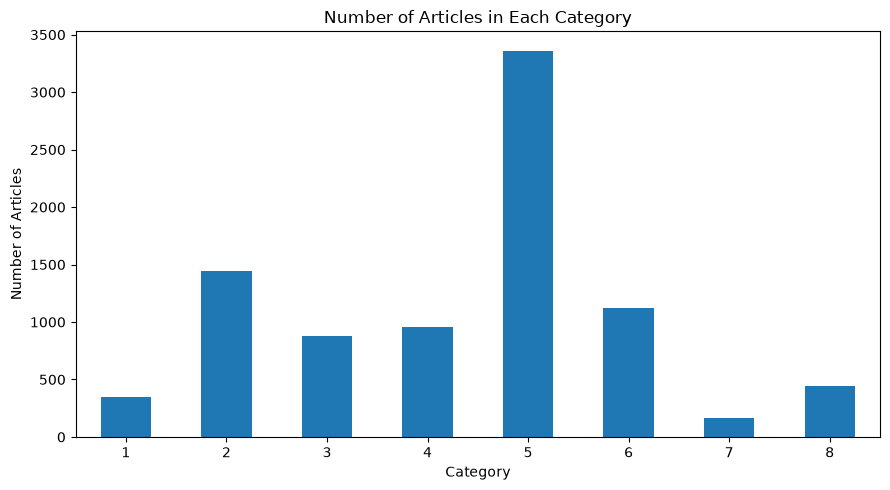

In [38]:
plt.figure(figsize=(9, 5))

category_counts.plot(kind="bar")

plt.title("Number of Articles in Each Category")
plt.xlabel("Category")
plt.ylabel("Number of Articles")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

##  رسم نمودار طول متن‌ها

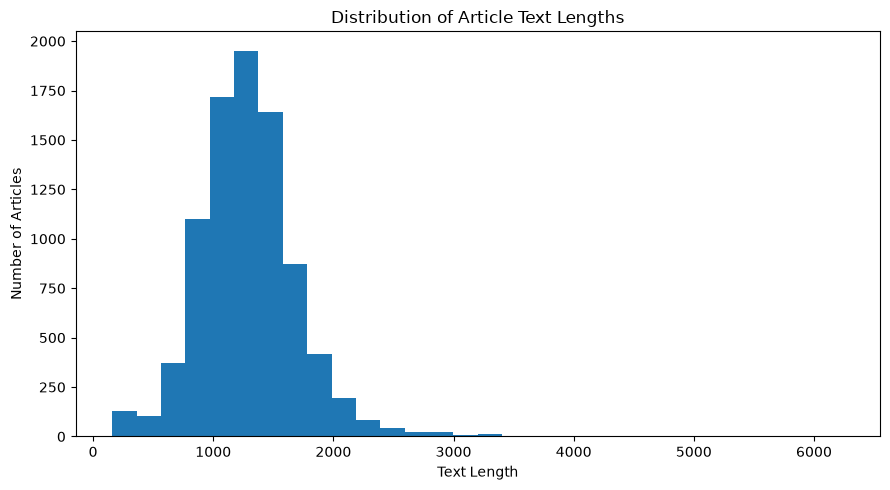

In [53]:
plt.figure(figsize=(9, 5))

plt.hist(text_lengths, bins=30)

plt.title("Distribution of Article Text Lengths")
plt.xlabel("Text Length")
plt.ylabel("Number of Articles")

plt.tight_layout()
plt.show()

## جدا کردن عنوان و چکیده

In [39]:
def split_text(text):

    parts = str(text).split("\n\n", 1)

    title = parts[0].strip()

    abstract = parts[1].strip() if len(parts) > 1 else ""

    return pd.Series([title, abstract])


train[["title", "abstract"]] = train["sentences"].apply(split_text)

test[["title", "abstract"]] = test["sentences"].apply(split_text)

display(
    train[["title", "abstract", "labels"]].head()
)

,title,abstract,labels
0,تحلیلی بر اثرات سامانه های آبیاری نوین بر نواح...,"روند کاهشی میزان منابع آبی در کشور, مسئولان مر...",2
1,نقش نوآوری و رضایتمندی بر بهزیستی ذهنی و قصد ر...,"با شیوع ویروس کرونا, موضوع گردشگری مجازی یکی ا...",5
2,بررسی ساختار معنایی جمله در زبانشناسی روسی,امروزه زبان شناسان روس بیش از گذشته توجه خود ر...,5
3,تحلیل الگوی رشد کالبدی-فضایی شهرها از طریق آما...,برنامه ریزی شهری از گذشته تا به امروز بیشتر بر...,6
4,تأثیر ترکیب قید سرعت با قیود روش های صریح، بدو...,وقتی ورزشکاری از درجات آزادی رهاشده ی خود نهای...,5


## پاک‌سازی داده‌های ناقص

In [40]:
train_clean = train.dropna(
    subset=["sentences", "labels"]
).copy()

test_clean = test.dropna(
    subset=["sentences", "labels"]
).copy()

train_clean = train_clean[
    train_clean["sentences"].astype(str).str.strip() != ""
].copy()

test_clean = test_clean[
    test_clean["sentences"].astype(str).str.strip() != ""
].copy()

print("Train before cleaning:", len(train))
print("Train after cleaning:", len(train_clean))

print("Test before cleaning:", len(test))
print("Test after cleaning:", len(test_clean))

Train before cleaning: 8712
Train after cleaning: 8712
Test before cleaning: 3735
Test after cleaning: 3735


## بررسی تکرار بین آموزش و آزمون

In [41]:
common_articles_df = train_clean[
    train_clean["sentences"].isin(common_articles)
][["sentences", "labels"]].merge(
    test_clean[["sentences", "labels"]],
    on="sentences",
    how="inner",
    suffixes=("_train", "_test")
)

print("Number of shared articles:", len(common_articles_df))

display(common_articles_df)

Number of shared articles: 2


,sentences,labels_train,labels_test
0,نشانه شناسی تطبیقی آیین سوگ سیاوش و مجلس تعزیه...,7,7
1,سیاست های فرهنگی، هنری و تجاری قالی ایرانی دور...,6,6


## ذخیره‌ی داده‌های آماده

In [42]:
train_clean.to_csv(
    DATASET_PATH / "train_clean.csv",
    index=False,
    encoding="utf-8-sig"
)

test_clean.to_csv(
    DATASET_PATH / "test_clean.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Clean datasets saved successfully!")

Clean datasets saved successfully!


## ساخت پرس‌وجوهای آزمایشی

In [43]:
queries = [
    "کاربرد هوش مصنوعی در پزشکی",
    "یادگیری ماشین در تشخیص بیماری",
    "آلودگی آب و محیط زیست",
    "مدیریت منابع آب",
    "گردشگری و توسعه اقتصادی",
    "معماری پایدار",
    "آموزش مجازی",
    "اقتصاد ایران",
    "کشاورزی هوشمند",
    "مدیریت شهری",
    "حقوق بین الملل",
    "فناوری نانو",
    "روانشناسی اجتماعی",
    "دامپزشکی",
    "علوم کامپیوتر"
]

evaluation_queries = pd.DataFrame({
    "query": queries
})

display(evaluation_queries)

,query
0,کاربرد هوش مصنوعی در پزشکی
1,یادگیری ماشین در تشخیص بیماری
2,آلودگی آب و محیط زیست
3,مدیریت منابع آب
4,گردشگری و توسعه اقتصادی
5,معماری پایدار
6,آموزش مجازی
7,اقتصاد ایران
8,کشاورزی هوشمند
9,مدیریت شهری


## ذخیره‌ی پرس‌وجوها

In [44]:
evaluation_queries.to_csv(
    DATASET_PATH / "evaluation_queries.csv",
    index=False,
    encoding="utf-8-sig"
)

## آماده‌سازی جدول نتایج ارزیابی

In [45]:
evaluation_results = pd.DataFrame(
    columns=[
        "query",
        "article_title",
        "rank",
        "relevant"
    ]
)

display(evaluation_results)

,query,article_title,rank,relevant


##  محاسبه‌ی Precision@5

In [46]:
def precision_at_5(relevance):

    top_5 = relevance[:5]

    if len(top_5) == 0:
        return 0

    return sum(top_5) / 5

## محاسبه‌ی میانگین نتایج

In [47]:
if not evaluation_results.empty:

    scores = (
        evaluation_results
        .sort_values("rank")
        .groupby("query")["relevant"]
        .apply(lambda x: precision_at_5(x.tolist()))
    )

    print("Precision@5 for each query:")
    display(scores)

    print("Average Precision@5:")
    print(round(scores.mean(), 3))

## نمودار نتایج ارزیابی

In [48]:
if not evaluation_results.empty:

    scores = (
        evaluation_results
        .sort_values("rank")
        .groupby("query")["relevant"]
        .apply(lambda x: precision_at_5(x.tolist()))
    )

    scores.plot(
        kind="bar",
        figsize=(10, 5)
    )

    plt.title("Precision@5 for Each Query")
    plt.xlabel("Query")
    plt.ylabel("Precision@5")

    plt.ylim(0, 1)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()